# Local music genre organizer — pilot baseline
Mariia Liutenko · 73952

This notebook inspects the real pilot data, a spectrogram, the trained CNN and its held-out results. Training is implemented in `src/train.py`. The pilot has 560 FMA-small tracks, rather than the full 8,000-track dataset.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if (ROOT / 'project').is_dir():
    ROOT = ROOT / 'project'
assert (ROOT / 'src' / 'audio.py').exists(), 'Open this notebook from the repository or project folder.'
sys.path.insert(0, str(ROOT.parent))
from project.src.audio import prepare
from project.src.model import GenreCNN
torch.set_num_threads(2)
print('Project:', ROOT.name)

Project: project


## 1. Data and splits
We sample independently inside each official split, using seed 42. One track supplies one middle five-second segment. Training, validation and test tracks stay separate; artist overlap is checked too.

In [2]:
manifest = pd.read_csv(ROOT / 'results' / 'manifest.csv')
print(manifest.groupby(['split', 'genre']).size().unstack().to_string())
assert manifest.track_id.is_unique
artist_sets = {s: set(g.artist_id) for s, g in manifest.groupby('split')}
for a, b in [('training','validation'),('training','test'),('validation','test')]:
    assert not artist_sets[a] & artist_sets[b]
print('Unique tracks; no artist overlap between splits.')

genre       Electronic  Experimental  Folk  Hip-Hop  Instrumental  International  Pop  Rock
split                                                                                      
test                10            10    10       10            10             10   10    10
training            50            50    50       50            50             50   50    50
validation          10            10    10       10            10             10   10    10
Unique tracks; no artist overlap between splits.


## 2. Audio becomes an image
Decode the middle five seconds, convert to mono, resample to 22,050 Hz, compute an STFT, map power to 64 mel bands and take log10. The network receives one channel with 64 bands and 216 time frames.

Input shape: (1, 64, 216)
Preparation times (ms): {'audio_loading_ms': 13.017600000239327, 'spectrogram_ms': 5.328600000211736}


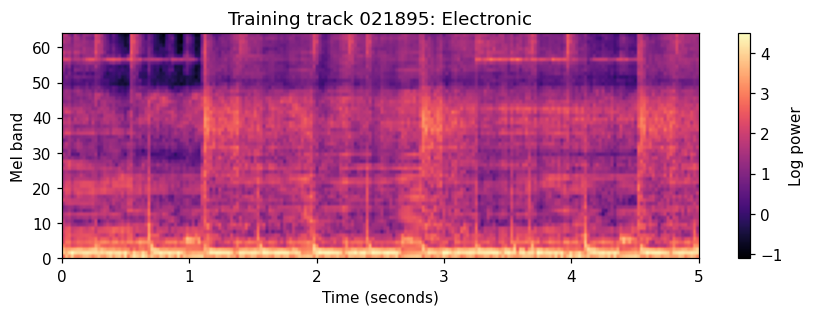

In [3]:
row = manifest.loc[manifest.split == 'training'].iloc[0]
feature, preparation_times = prepare(ROOT / row.path)
print('Input shape:', tuple(feature.shape))
print('Preparation times (ms):', preparation_times)
plt.figure(figsize=(8, 3))
plt.imshow(feature[0].numpy(), origin='lower', aspect='auto', extent=[0,5,0,64], cmap='magma')
plt.xlabel('Time (seconds)'); plt.ylabel('Mel band')
plt.title(f'Training track {row.track_id:06d}: {row.genre}')
plt.colorbar(label='Log power'); plt.tight_layout(); plt.show()

## 3. CNN and training
Three convolution blocks extract patterns. Global average pooling and a linear layer produce eight genre scores. Cross-entropy compares scores to training labels; backpropagation and Adam update weights. Input mean and standard deviation are fitted on training data only.

To reproduce training from the repository root, run `python -m project.src.train --epochs 20` using the project environment. This notebook reads that run's saved results and does not retrain when opened.

GenreCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=1)
    (12): Flatten(start_dim=1, end_dim=-1)
  )
  (classifier): Linear(in_features=64, out_features=8, bias=True)
)
Trainable parameters: 24040
Genre order: ['Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instru

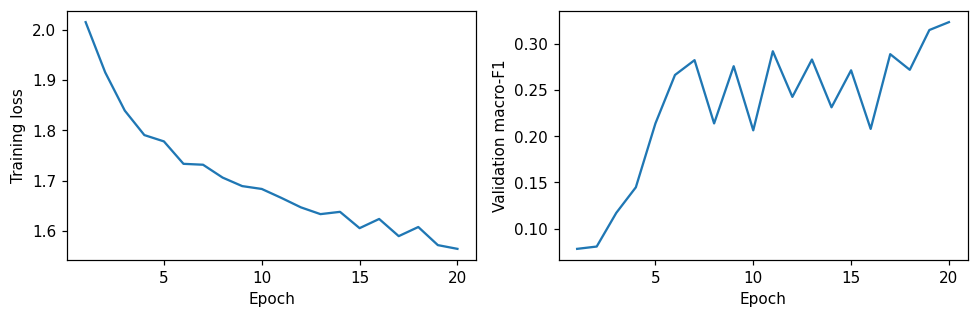

In [4]:
print(GenreCNN())
config = json.loads((ROOT / 'results' / 'model_config.json').read_text())
model = torch.jit.load(str(ROOT / 'results' / 'genre_cnn.pt'), map_location='cpu').eval()
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))
print('Genre order:', config['genres'])
print('Best validation epoch:', config['best_epoch'])
history = pd.read_csv(ROOT / 'results' / 'history.csv')
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(history.epoch, history.train_loss); axes[0].set(xlabel='Epoch', ylabel='Training loss')
axes[1].plot(history.epoch, history.validation_macro_f1); axes[1].set(xlabel='Epoch', ylabel='Validation macro-F1')
plt.tight_layout(); plt.show()

## 4. Held-out quality and automatic tagging
The checkpoint and confidence threshold are selected on validation only. The largest softmax score gives a suggested genre. Scores below the threshold require human review. A score above 1 disables automatic tagging if validation provides no qualifying threshold.

Accuracy measures overall correct predictions. Macro-F1 averages F1 equally across all eight genres. Coverage is the fraction tagged automatically; accepted accuracy is the fraction of those automatic tags that are correct. Both 80% accepted accuracy and 50% test coverage are needed to meet the tagging target.

Test accuracy: 0.425
Test macro-F1: 0.3843
Validation selected threshold: 1.01
Validation selective results: {'accepted': 0, 'total': 80, 'coverage': 0.0, 'accuracy_among_accepted': None, 'target_met': False}
Test selective results: {'accepted': 0, 'total': 80, 'coverage': 0.0, 'accuracy_among_accepted': None, 'target_met': False}


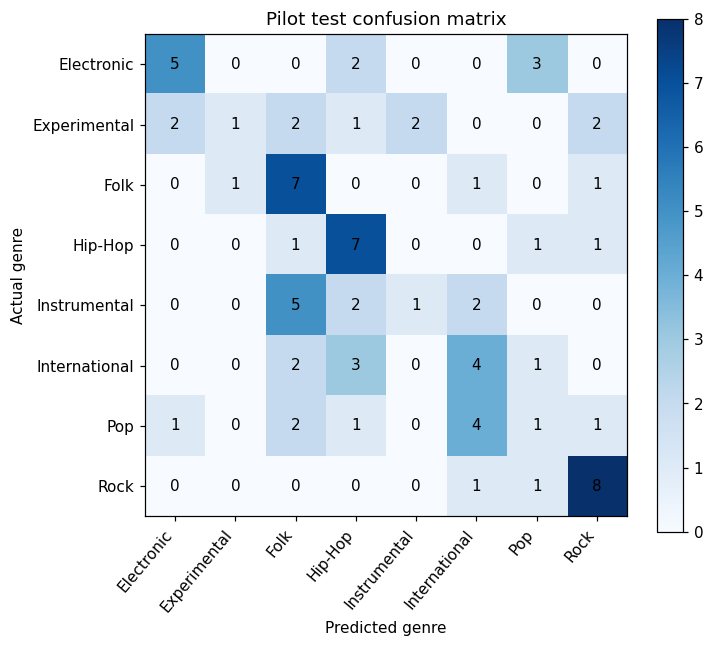

In [5]:
metrics = json.loads((ROOT / 'results' / 'metrics.json').read_text())
print('Test accuracy:', round(metrics['accuracy'], 4))
print('Test macro-F1:', round(metrics['macro_f1'], 4))
print('Validation selected threshold:', metrics['threshold'])
print('Validation selective results:', metrics['validation_selective'])
print('Test selective results:', metrics['test_selective'])
cm = pd.read_csv(ROOT / 'results' / 'confusion_matrix.csv', index_col=0)
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(cm.values, cmap='Blues')
ax.set_xticks(range(8), cm.columns, rotation=50, ha='right')
ax.set_yticks(range(8), cm.index)
ax.set(xlabel='Predicted genre', ylabel='Actual genre', title='Pilot test confusion matrix')
for i in range(8):
    for j in range(8):
        ax.text(j, i, str(cm.iloc[i,j]), ha='center', va='center')
fig.colorbar(image, ax=ax); plt.tight_layout(); plt.show()

## 5. Size and CPU timing
The proposal's 50 ms limit covers a warmed model forward from a ready spectrogram, batch size one. Decoding and spectrogram preparation are measured separately. The table also shows complete file-to-prediction time. The deployed file must be at most 5 MB.

In [6]:
print('Model size (MB):', round(metrics['model_bytes'] / 1e6, 3))
print('Warm forward p95 (ms):', round(metrics['forward_p95_ms'], 3))
print('Model size target met:', metrics['model_size_limit_met'])
print('Forward latency target met:', metrics['latency_limit_met'])
timings = pd.read_csv(ROOT / 'results' / 'timings.csv')
print(timings[['audio_loading_ms','spectrogram_ms','forward_ms','total_ms']].quantile([0.5,0.95]).round(3).to_string())
print('Protocol:', metrics['latency_protocol'])

Model size (MB): 0.129
Warm forward p95 (ms): 2.601
Model size target met: True
Forward latency target met: True
      audio_loading_ms  spectrogram_ms  forward_ms  total_ms
0.50            14.015           1.449       2.752    18.578
0.95            18.781           2.016       4.223    23.066
Protocol: {'device': 'CPU', 'batch_size': 1, 'threads': 2, 'warmup': 20, 'repeats': 200, 'input': [1, 1, 64, 216], 'includes_preprocessing': False}


## 6. One local prediction
The same preprocessing and saved model are used in the local app. Review decisions are exported to CSV, with no changes to the original audio. This small pilot supports only the dataset's eight genres; full-data training and INT8 quantization remain future work.

In [7]:
from project.src.predict import Predictor
example = manifest.loc[manifest.split == 'test'].iloc[0]
result = Predictor().predict(ROOT / example.path)
print('Track:', int(example.track_id), '| actual:', example.genre)
print(json.dumps(result, indent=2))

Track: 13706 | actual: Electronic
{
  "suggested_genre": "Hip-Hop",
  "confidence": 0.45478522777557373,
  "status": "needs_review",
  "threshold": 1.01,
  "scores": {
    "Electronic": 0.2580835521221161,
    "Experimental": 0.020231720060110092,
    "Folk": 0.0032170661725103855,
    "Hip-Hop": 0.45478522777557373,
    "Instrumental": 0.009112869389355183,
    "International": 0.12878750264644623,
    "Pop": 0.11034199595451355,
    "Rock": 0.015440077520906925
  },
  "audio_loading_ms": 11.232999999265303,
  "spectrogram_ms": 1.3438000005407957,
  "forward_ms": 2.086099999360158,
  "total_ms": 20.089900001039496
}
